# KAMARA — Treinamento BERTimbau v2

Notebook Colab para treinar o classificador textual do KAMARA com `neuralmind/bert-base-portuguese-cased` sobre o dataset NLP v2.

**Protocolo experimental**

- usa apenas `train.jsonl` e `validation.jsonl`;
- **não usa `test.jsonl`**;
- entrada do modelo: somente `text`;
- alvo: `target_label`;
- preserva o texto bruto;
- seleciona o melhor checkpoint por `macro_f1` na validação;
- salva métricas, predições, erros, matriz de confusão, histórico e metadados;
- exporta modelo + avaliação em `kamara_bertimbau_v2_export.zip`.

Configuração mantida comparável à rodada anterior: `max_length=128`, LR `2e-5`, 3 épocas, weight decay `0.01`, warmup `0.10`, batch físico `16`, gradient accumulation `2`, batch efetivo `32`, eval batch `32`, early stopping patience `2`, seed `20260830`.

In [1]:
# 1) Dependências
!pip -q install "transformers>=4.45,<5" "datasets>=3,<4" "accelerate>=1,<2" scikit-learn pandas matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 75.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
# 2) Imports, seed e configuração
import os
import json
import random
import shutil
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from datasets import Dataset
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    set_seed,
)

SEED = 20260830
MODEL_NAME = "neuralmind/bert-base-portuguese-cased"
RUN_NAME = "kamara_bertimbau_v2"
MAX_LENGTH = 128
LEARNING_RATE = 2e-5
EPOCHS = 3
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.10
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
GRAD_ACCUM_STEPS = 2

set_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)
if not torch.cuda.is_available():
    print("AVISO: altere o runtime do Colab para GPU antes do treinamento.")

PyTorch: 2.11.0+cu128
CUDA disponível: True
GPU: Tesla T4


## Upload dos splits

Envie **somente** `train.jsonl` e `validation.jsonl` gerados pelo split v2. Não envie `test.jsonl`.

In [3]:
# 3) Upload dos dados
from google.colab import files

uploaded = files.upload()
required = {"train.jsonl", "validation.jsonl"}
missing = required - set(uploaded.keys())
if missing:
    raise RuntimeError(f"Arquivos ausentes: {sorted(missing)}")
if "test.jsonl" in uploaded:
    raise RuntimeError("test.jsonl foi enviado. O conjunto de teste deve permanecer intocado.")

TRAIN_PATH = Path("/content/train.jsonl")
VAL_PATH = Path("/content/validation.jsonl")
print("Train:", TRAIN_PATH)
print("Validation:", VAL_PATH)
print("TESTE NÃO SERÁ UTILIZADO.")

Saving validation.jsonl to validation.jsonl
Saving train.jsonl to train.jsonl
Train: /content/train.jsonl
Validation: /content/validation.jsonl
TESTE NÃO SERÁ UTILIZADO.


In [4]:
# 4) Leitura e validação estrutural

def read_jsonl(path):
    rows = []
    with Path(path).open("r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise RuntimeError(f"JSON inválido em {path}, linha {line_no}") from exc
    return rows

train_records = read_jsonl(TRAIN_PATH)
val_records = read_jsonl(VAL_PATH)

required_fields = {"sample_id", "text", "target_label"}
for split_name, rows in [("train", train_records), ("validation", val_records)]:
    for i, row in enumerate(rows):
        missing_fields = required_fields - set(row.keys())
        if missing_fields:
            raise RuntimeError(f"{split_name}[{i}] sem campos: {sorted(missing_fields)}")

assert len(train_records) == 6300, len(train_records)
assert len(val_records) == 1350, len(val_records)
train_ids = {r["sample_id"] for r in train_records}
val_ids = {r["sample_id"] for r in val_records}
assert len(train_ids) == len(train_records)
assert len(val_ids) == len(val_records)
assert train_ids.isdisjoint(val_ids)

print("Train:", len(train_records))
print("Validation:", len(val_records))
print("Integridade básica: OK")

Train: 6300
Validation: 1350
Integridade básica: OK


In [5]:
# 5) Classes e distribuição
LABELS = [
    "COBRADE_1_2_1_0_0",
    "COBRADE_1_2_2_0_0",
    "COBRADE_1_2_3_0_0",
    "COBRADE_1_4_1_3_1",
    "COBRADE_1_4_1_3_2",
    "COBRADE_2_3_1_1_0",
    "COBRADE_2_3_1_2_0",
    "OTHER",
    "INSUFFICIENT_INFO",
]
label2id = {label: i for i, label in enumerate(LABELS)}
id2label = {i: label for label, i in label2id.items()}

for split_name, rows, expected in [
    ("train", train_records, 700),
    ("validation", val_records, 150),
]:
    found = {r["target_label"] for r in rows}
    unknown = found - set(LABELS)
    if unknown:
        raise RuntimeError(f"Labels desconhecidos em {split_name}: {sorted(unknown)}")
    counts = pd.Series([r["target_label"] for r in rows]).value_counts().reindex(LABELS)
    print(f"\n{split_name}")
    print(counts)
    assert (counts == expected).all(), f"Distribuição inesperada em {split_name}"

print("\nDistribuição por classe: OK")


train
COBRADE_1_2_1_0_0    700
COBRADE_1_2_2_0_0    700
COBRADE_1_2_3_0_0    700
COBRADE_1_4_1_3_1    700
COBRADE_1_4_1_3_2    700
COBRADE_2_3_1_1_0    700
COBRADE_2_3_1_2_0    700
OTHER                700
INSUFFICIENT_INFO    700
Name: count, dtype: int64

validation
COBRADE_1_2_1_0_0    150
COBRADE_1_2_2_0_0    150
COBRADE_1_2_3_0_0    150
COBRADE_1_4_1_3_1    150
COBRADE_1_4_1_3_2    150
COBRADE_2_3_1_1_0    150
COBRADE_2_3_1_2_0    150
OTHER                150
INSUFFICIENT_INFO    150
Name: count, dtype: int64

Distribuição por classe: OK


In [6]:
# 6) Dataset e tokenização — somente text é entrada do modelo

def make_dataset(rows):
    return Dataset.from_dict({
        "text": [r["text"] for r in rows],
        "labels": [label2id[r["target_label"]] for r in rows],
        "sample_id": [r["sample_id"] for r in rows],
    })

train_ds = make_dataset(train_records)
val_ds = make_dataset(val_records)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH, padding=False)

train_tok = train_ds.map(tokenize, batched=True).remove_columns(["text", "sample_id"])
val_tok = val_ds.map(tokenize, batched=True).remove_columns(["text", "sample_id"])

lengths = [len(tokenizer(r["text"], truncation=False)["input_ids"]) for r in train_records + val_records]
s = pd.Series(lengths)
print("p50/p90/p95/p99/max:", *(int(s.quantile(q)) for q in [0.50, 0.90, 0.95, 0.99]), int(s.max()))
print(f"Textos > {MAX_LENGTH} tokens:", int((s > MAX_LENGTH).sum()))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/6300 [00:00<?, ? examples/s]

Map:   0%|          | 0/1350 [00:00<?, ? examples/s]

p50/p90/p95/p99/max: 21 35 40 49 89
Textos > 128 tokens: 0


In [7]:
# 7) Modelo e métricas
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABELS),
    id2label=id2label,
    label2id=label2id,
)

def compute_metrics(eval_pred):
    logits, y_true = eval_pred
    y_pred = np.argmax(logits, axis=-1)
    acc = accuracy_score(y_true, y_pred)
    mp, mr, mf1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    _, _, wf1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {
        "accuracy": acc,
        "macro_precision": mp,
        "macro_recall": mr,
        "macro_f1": mf1,
        "weighted_f1": wf1,
    }

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at neuralmind/bert-base-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [8]:
# 8) TrainingArguments e Trainer
OUTPUT_DIR = Path(f"/content/{RUN_NAME}_checkpoints")
MODEL_DIR = Path(f"/content/{RUN_NAME}")
EVAL_DIR = Path(f"/content/{RUN_NAME}_evaluation")
for p in [OUTPUT_DIR, MODEL_DIR, EVAL_DIR]:
    if p.exists():
        shutil.rmtree(p)
    p.mkdir(parents=True, exist_ok=True)

kwargs = dict(
    output_dir=str(OUTPUT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    per_device_eval_batch_size=EVAL_BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    num_train_epochs=EPOCHS,
    weight_decay=WEIGHT_DECAY,
    warmup_ratio=WARMUP_RATIO,
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=25,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=SEED,
    data_seed=SEED,
    report_to="none",
    fp16=torch.cuda.is_available(),
)
params = inspect.signature(TrainingArguments.__init__).parameters
if "eval_strategy" in params:
    kwargs["eval_strategy"] = "epoch"
elif "evaluation_strategy" in params:
    kwargs["evaluation_strategy"] = "epoch"
else:
    raise RuntimeError("TrainingArguments incompatível: estratégia de avaliação não encontrada.")

training_args = TrainingArguments(**kwargs)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
print("Trainer pronto.")

Trainer pronto.


In [9]:
# 9) Treinamento
train_result = trainer.train()
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best macro_f1:", trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
1,0.202000,0.105285,0.984444,0.985115,0.984444,0.984481,0.984481
2,0.035900,0.029566,0.994074,0.994208,0.994074,0.994065,0.994065
3,0.012700,0.016941,0.997778,0.997802,0.997778,0.997773,0.997773


Best checkpoint: /content/kamara_bertimbau_v2_checkpoints/checkpoint-591
Best macro_f1: 0.9977726904673874


In [10]:
# 10) Avaliação detalhada em VALIDATION
prediction_output = trainer.predict(val_tok)
logits = prediction_output.predictions
y_true = prediction_output.label_ids
y_pred = np.argmax(logits, axis=-1)
probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
confidence = probs[np.arange(len(y_pred)), y_pred]

pred_df = pd.DataFrame({
    "sample_id": [r["sample_id"] for r in val_records],
    "true_label": [id2label[int(i)] for i in y_true],
    "predicted_label": [id2label[int(i)] for i in y_pred],
    "correct": (y_true == y_pred).astype(int),
    "predicted_probability": confidence,
    "linguistic_profile": [r.get("linguistic_profile") for r in val_records],
    "difficulty": [r.get("difficulty") for r in val_records],
    "scenario_family": [r.get("scenario_family") for r in val_records],
    "text": [r["text"] for r in val_records],
})
errors_df = pred_df[pred_df["correct"] == 0].copy()

acc = accuracy_score(y_true, y_pred)
mp, mr, mf1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
_, _, wf1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
metrics = {
    "split": "validation",
    "records": len(val_records),
    "accuracy": round(float(acc), 6),
    "macro_precision": round(float(mp), 6),
    "macro_recall": round(float(mr), 6),
    "macro_f1": round(float(mf1), 6),
    "weighted_f1": round(float(wf1), 6),
    "errors": int((y_true != y_pred).sum()),
    "labels": LABELS,
}
print(json.dumps(metrics, ensure_ascii=False, indent=2))
print("\nErros de validation:", len(errors_df))
display(errors_df)
print("\nTESTE NÃO FOI UTILIZADO.")

{
  "split": "validation",
  "records": 1350,
  "accuracy": 0.997778,
  "macro_precision": 0.997802,
  "macro_recall": 0.997778,
  "macro_f1": 0.997773,
  "weighted_f1": 0.997773,
  "errors": 3,
  "labels": [
    "COBRADE_1_2_1_0_0",
    "COBRADE_1_2_2_0_0",
    "COBRADE_1_2_3_0_0",
    "COBRADE_1_4_1_3_1",
    "COBRADE_1_4_1_3_2",
    "COBRADE_2_3_1_1_0",
    "COBRADE_2_3_1_2_0",
    "OTHER",
    "INSUFFICIENT_INFO"
  ]
}

Erros de validation: 3


,sample_id,true_label,predicted_label,correct,predicted_probability,linguistic_profile,difficulty,scenario_family,text
1298,other_v2_0664,OTHER,COBRADE_1_2_3_0_0,0,0.716684,formal,intermediate,water_contamination,A água de abastecimento apresenta característi...
1299,other_v2_0665,OTHER,INSUFFICIENT_INFO,0,0.900030,formal,hard,water_contamination,Foram relatados indícios de contaminação no po...
1333,other_v2_0896,OTHER,COBRADE_1_2_3_0_0,0,0.941261,indirect,hard,dam_failure,BARRAGEM CEDEU AQ 😰 abriu um vao e a agua ta s...



TESTE NÃO FOI UTILIZADO.


,target_label,precision,recall,f1_score,support
0,COBRADE_1_2_1_0_0,1.000000,1.00,1.000000,150
1,COBRADE_1_2_2_0_0,1.000000,1.00,1.000000,150
2,COBRADE_1_2_3_0_0,0.986842,1.00,0.993377,150
3,COBRADE_1_4_1_3_1,1.000000,1.00,1.000000,150
4,COBRADE_1_4_1_3_2,1.000000,1.00,1.000000,150
5,COBRADE_2_3_1_1_0,1.000000,1.00,1.000000,150
6,COBRADE_2_3_1_2_0,1.000000,1.00,1.000000,150
7,OTHER,1.000000,0.98,0.989899,150
8,INSUFFICIENT_INFO,0.993377,1.00,0.996678,150


,COBRADE_1_2_1_0_0,COBRADE_1_2_2_0_0,COBRADE_1_2_3_0_0,COBRADE_1_4_1_3_1,COBRADE_1_4_1_3_2,COBRADE_2_3_1_1_0,COBRADE_2_3_1_2_0,OTHER,INSUFFICIENT_INFO
COBRADE_1_2_1_0_0,150,0,0,0,0,0,0,0,0
COBRADE_1_2_2_0_0,0,150,0,0,0,0,0,0,0
COBRADE_1_2_3_0_0,0,0,150,0,0,0,0,0,0
COBRADE_1_4_1_3_1,0,0,0,150,0,0,0,0,0
COBRADE_1_4_1_3_2,0,0,0,0,150,0,0,0,0
COBRADE_2_3_1_1_0,0,0,0,0,0,150,0,0,0
COBRADE_2_3_1_2_0,0,0,0,0,0,0,150,0,0
OTHER,0,0,2,0,0,0,0,147,1
INSUFFICIENT_INFO,0,0,0,0,0,0,0,0,150


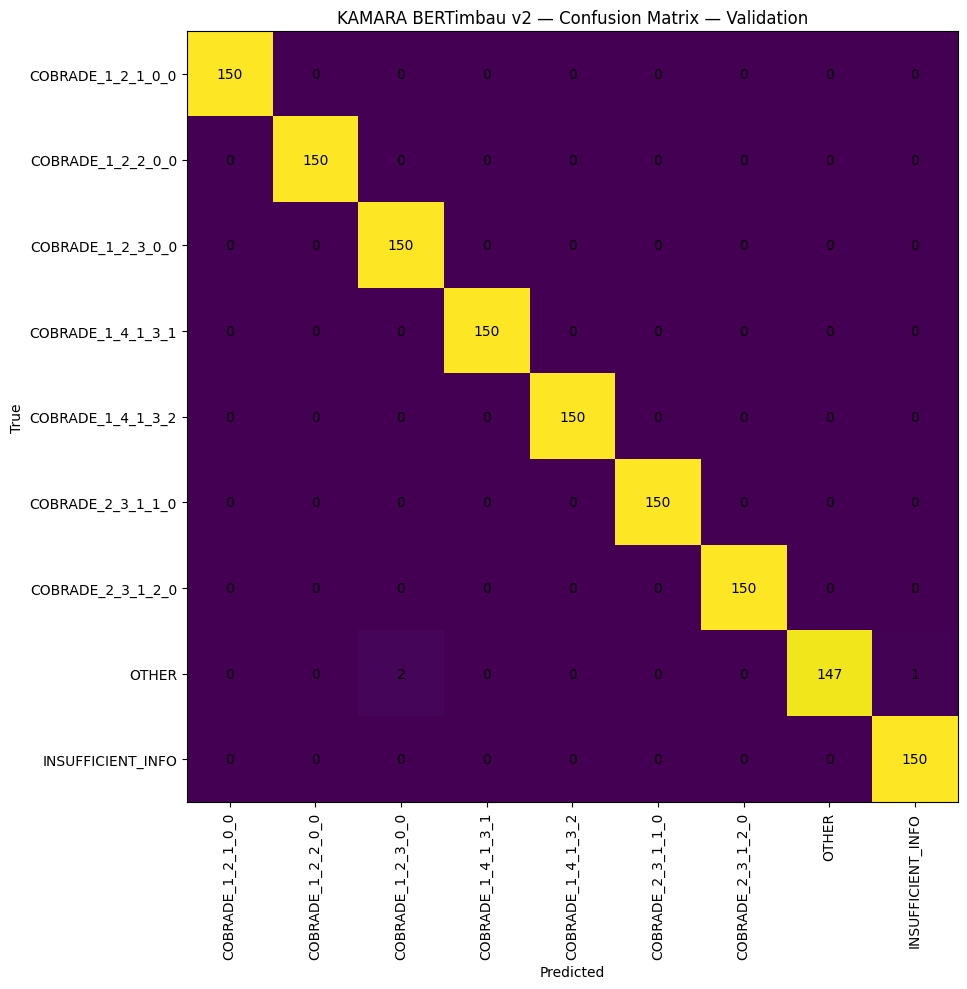

In [11]:
# 11) Métricas por classe + matriz de confusão
report = classification_report(
    y_true, y_pred,
    labels=list(range(len(LABELS))),
    target_names=LABELS,
    output_dict=True,
    zero_division=0,
)
per_class_df = pd.DataFrame([
    {
        "target_label": label,
        "precision": report[label]["precision"],
        "recall": report[label]["recall"],
        "f1_score": report[label]["f1-score"],
        "support": int(report[label]["support"]),
    }
    for label in LABELS
])
display(per_class_df)

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(LABELS))))
cm_df = pd.DataFrame(cm, index=LABELS, columns=LABELS)
display(cm_df)

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(cm)
ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))
ax.set_xticklabels(LABELS, rotation=90)
ax.set_yticklabels(LABELS)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("KAMARA BERTimbau v2 — Confusion Matrix — Validation")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.tight_layout()
plt.show()

In [12]:
# 12) Salvar artefatos, avaliação e metadados
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))

pred_df.to_csv(EVAL_DIR / "predictions_validation.csv", index=False, encoding="utf-8")
errors_df.to_csv(EVAL_DIR / "errors_validation.csv", index=False, encoding="utf-8")
per_class_df.to_csv(EVAL_DIR / "per_class_metrics_validation.csv", index=False, encoding="utf-8")
cm_df.to_csv(EVAL_DIR / "confusion_matrix_validation.csv", encoding="utf-8")
pd.DataFrame(trainer.state.log_history).to_csv(EVAL_DIR / "training_history.csv", index=False, encoding="utf-8")

with (EVAL_DIR / "metrics_validation.json").open("w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

fig, ax = plt.subplots(figsize=(12, 10))
ax.imshow(cm)
ax.set_xticks(range(len(LABELS)))
ax.set_yticks(range(len(LABELS)))
ax.set_xticklabels(LABELS, rotation=90)
ax.set_yticklabels(LABELS)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("KAMARA BERTimbau v2 — Confusion Matrix — Validation")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")
fig.tight_layout()
fig.savefig(EVAL_DIR / "confusion_matrix_validation.png", dpi=180)
plt.close(fig)

import transformers, datasets, sklearn
run_metadata = {
    "run_name": RUN_NAME,
    "model_name": MODEL_NAME,
    "dataset_iteration": "v2",
    "task": "multiclass_text_classification",
    "input_feature": "text",
    "target": "target_label",
    "train_records": len(train_records),
    "validation_records": len(val_records),
    "test_used": False,
    "labels": LABELS,
    "seed": SEED,
    "max_length": MAX_LENGTH,
    "learning_rate": LEARNING_RATE,
    "epochs_requested": EPOCHS,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "effective_train_batch_size": TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS,
    "weight_decay": WEIGHT_DECAY,
    "warmup_ratio": WARMUP_RATIO,
    "early_stopping_patience": 2,
    "best_model_metric": "macro_f1",
    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_metric": trainer.state.best_metric,
    "validation_metrics": metrics,
    "runtime": {
        "python": os.sys.version,
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "datasets": datasets.__version__,
        "scikit_learn": sklearn.__version__,
        "cuda_available": torch.cuda.is_available(),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    },
}
with (MODEL_DIR / "run_metadata.json").open("w", encoding="utf-8") as f:
    json.dump(run_metadata, f, ensure_ascii=False, indent=2)

print("Modelo:", MODEL_DIR)
print("Avaliação:", EVAL_DIR)

Modelo: /content/kamara_bertimbau_v2
Avaliação: /content/kamara_bertimbau_v2_evaluation


In [13]:
# 13) Exportar ZIP para o repositório local
EXPORT_ROOT = Path("/content/kamara_bertimbau_v2_export")
if EXPORT_ROOT.exists():
    shutil.rmtree(EXPORT_ROOT)

artifact_target = EXPORT_ROOT / "artifacts" / RUN_NAME
eval_target = EXPORT_ROOT / "evaluation" / RUN_NAME
artifact_target.mkdir(parents=True, exist_ok=True)
eval_target.mkdir(parents=True, exist_ok=True)

for src in MODEL_DIR.iterdir():
    if src.is_file():
        shutil.copy2(src, artifact_target / src.name)
for src in EVAL_DIR.iterdir():
    if src.is_file():
        shutil.copy2(src, eval_target / src.name)

zip_path = shutil.make_archive("/content/kamara_bertimbau_v2_export", "zip", EXPORT_ROOT)
print("ZIP criado:", zip_path)
print("TESTE NÃO FOI UTILIZADO.")

ZIP criado: /content/kamara_bertimbau_v2_export.zip
TESTE NÃO FOI UTILIZADO.


In [14]:
# 14) Baixar ZIP final
from google.colab import files
files.download("/content/kamara_bertimbau_v2_export.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Destino local após baixar

Extraia o ZIP e copie para:

```text
ml/artifacts/nlp/kamara_bertimbau_v2/
ml/evaluation/nlp/kamara_bertimbau_v2/
```

Depois disso, faça a análise da validação e o stress test do BERTimbau v2. O `test.jsonl` continua congelado até a etapa final.